# Blocks, tiles and slices

**The question.** Treat the tensor as a cube. Can we cut it into small blocks
and run an SVD on each -- or is that already what the paper does?

**Short answer.** Partly already, but not the blocks you would picture. The
paper's transform operator `T` cuts the cube into whole *frontal slices*, one
block per face. Cutting each face into small *tiles* is a different thing, and
this notebook measures what it costs and buys on the paper's own reference
tensor.

Source: Panchal, Sahoo & Behera, *Tensor decomposition and neural architectures
through generalized Hadamard products*, Neurocomputing 699 (2026) 134372.

In [1]:
import os, sys, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, torch, cv2
from hadamard_ops import h_prod

dev = "cuda" if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture("../application-videos/video.mp4")
frames = []
while True:
    ok, f = cap.read()
    if not ok: break
    frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
cap.release()

A = torch.tensor(np.array(frames), dtype=torch.float32).permute(1, 2, 0, 3) / 255.0
m, n = A.shape[0], A.shape[1]
X = A.reshape(m, n, -1).permute(2, 0, 1).contiguous().to(dev)   # (S, m, n)
S = X.shape[0]
nsq = (X ** 2).sum()

print(f"tensor {tuple(A.shape)}  ->  {S} frontal slices of {m}x{n}")
print(f"device {dev}")
print(f"this is the Table 9 reference tensor (Carphone, 144x144x3x60)")

tensor (144, 144, 60, 3)  ->  180 frontal slices of 144x144
device cuda
this is the Table 9 reference tensor (Carphone, 144x144x3x60)


## 1. The paper's blocks are whole slices

`T` stacks the frontal slices `A(:,:,i3)` into a block matrix, and the block
Hadamard product does a matrix product *inside* each block, elementwise
*across* blocks. With `M = I` that makes the generalized Hadamard product
**facewise**: slice `i` of the output depends on slice `i` of the inputs and
nothing else.

Checked below against the repo's own `h_prod`.

In [2]:
torch.manual_seed(0)
mm, rr, nn, pp = 6, 4, 5, 7
Aa = torch.randn(mm, rr, pp, dtype=torch.float64)
Bb = torch.randn(rr, nn, pp, dtype=torch.float64)
C = h_prod(Aa, Bb)

d = max((C[:, :, i] - Aa[:, :, i] @ Bb[:, :, i]).abs().max().item()
        for i in range(pp))
print(f"max |C[:,:,i] - A[:,:,i] @ B[:,:,i]|  =  {d:.3e}")

# Perturb one input slice: which output slices move?
Bb2 = Bb.clone(); Bb2[:, :, 3] += 99.0
C2 = h_prod(Aa, Bb2)
moved = [i for i in range(pp)
         if (C2[:, :, i] - C[:, :, i]).abs().max().item() > 0]
print(f"perturbing input slice 3 changes output slices: {moved}")
print()
print("So the cube is ALREADY blocked -- into 180 independent faces.")
print("Nothing in this framework couples one frame to another.")

max |C[:,:,i] - A[:,:,i] @ B[:,:,i]|  =  8.882e-16
perturbing input slice 3 changes output slices: [3]

So the cube is ALREADY blocked -- into 180 independent faces.
Nothing in this framework couples one frame to another.


## 2. Tiling each face: the experiment

Cut every `144x144` slice into `a x a` tiles and truncate each tile's SVD at
rank `r'`. Compare against the slice-wise SVD (the paper's TSVD) **at matched
storage**, not matched rank -- matched rank would be the wrong comparison,
since a tiled fit stores a different number of values.

Storage, counting the factor entries kept:

| | per slice |
|---|---|
| slice-wise, rank `r` | `r(m+n)` |
| `a x a` tiles, rank `r'` | `(m/a)(n/a) * r' * 2a = 2 r' m n / a` |

The truncation error needs no reconstruction. Tiles are disjoint and cover the
slice, so the Frobenius error is additive over them and equals the tail of the
singular values: `||X - Y_r||_F^2 = sum_tiles sum_{k>r} s_k^2`.

In [3]:
def curve(a):
    """Exact error-vs-storage for a-by-a tiling, from singular-value tails."""
    t = X.reshape(S, m // a, a, n // a, a).permute(0, 1, 3, 2, 4).reshape(-1, a, a)
    s = torch.linalg.svdvals(t)                                  # (ntiles, a)
    tail = torch.flip(torch.cumsum(torch.flip(s ** 2, [1]), 1), [1])
    tail = torch.cat([tail, torch.zeros(tail.shape[0], 1, device=dev)], 1)
    per_r = tail.sum(0)
    tiles = (m // a) * (n // a)
    return [(r * 2 * a * tiles * S, (per_r[r] / nsq).sqrt().item())
            for r in range(1, a + 1)]

t0 = time.time()
TILES = [144, 72, 48, 36, 24, 18, 12]
curves = {a: curve(a) for a in TILES}
print(f"all {len(TILES)} curves in {time.time() - t0:.1f}s")

BASE = 518400          # slice-wise rank 10, the Table 9 operating point
base_err = dict(curves[144])[BASE]
print(f"\nslice-wise SVD, rank 10:  rel.err {base_err:.6f}   storage {BASE:,}")
print(f"paper Table 9 TSVD rank 10: rel.err 0.134775, PSNR 25.16 dB")
print("(independent pipeline, so the third digit differs -- this is a cross-check)")

all 7 curves in 6.4s

slice-wise SVD, rank 10:  rel.err 0.132975   storage 518,400
paper Table 9 TSVD rank 10: rel.err 0.134775, PSNR 25.16 dB
(independent pipeline, so the third digit differs -- this is a cross-check)


In [4]:
budgets = [259200, 518400, 777600, 1036800]
print(f"{'budget':>11} {'xbase':>7} | " + "".join(f"a={a:<6}" for a in TILES))
print("-" * 76)
for B in budgets:
    row = ""
    for a in TILES:
        ok = [e for c, e in curves[a] if c <= B]
        row += f"{min(ok):<8.4f}" if ok else "   --   "
    print(f"{B:>11,} {B/BASE:>6.2f}x | {row}")

print("\nbest tile size at each budget:")
for B in budgets:
    e, a = min((min([x for c, x in curves[t] if c <= B], default=9.0), t)
               for t in TILES)
    full = min([x for c, x in curves[144] if c <= B], default=9.0)
    gain = 100 * (full - e) / full
    print(f"  {B:>9,} ({B/BASE:.2f}x):  a={a:<4} rel.err {e:.4f}"
          f"   vs slice-wise {full:.4f}   ({gain:+.1f}%)")

     budget   xbase | a=144   a=72    a=48    a=36    a=24    a=18    a=12    
----------------------------------------------------------------------------
    259,200   0.50x | 0.2010  0.2302  0.2708  0.2328     --      --      --   
    518,400   1.00x | 0.1330  0.1269  0.1347  0.1471  0.1984  0.1630     --   
    777,600   1.50x | 0.0982  0.0993  0.0909  0.1100  0.1182  0.1630  0.1290  
  1,036,800   2.00x | 0.0759  0.0727  0.0775  0.0706  0.0805  0.0965  0.1290  

best tile size at each budget:
    259,200 (0.50x):  a=144  rel.err 0.2010   vs slice-wise 0.2010   (+0.0%)
    518,400 (1.00x):  a=72   rel.err 0.1269   vs slice-wise 0.1330   (+4.6%)
    777,600 (1.50x):  a=48   rel.err 0.0909   vs slice-wise 0.0982   (+7.5%)
  1,036,800 (2.00x):  a=36   rel.err 0.0706   vs slice-wise 0.0759   (+7.0%)


/tmp/ipykernel_1349559/3664085386.py:9: RuntimeWarning: divide by zero encountered in log
  out[ins] = np.exp(np.interp(np.log(grid[ins]), np.log(c), np.log(e)))


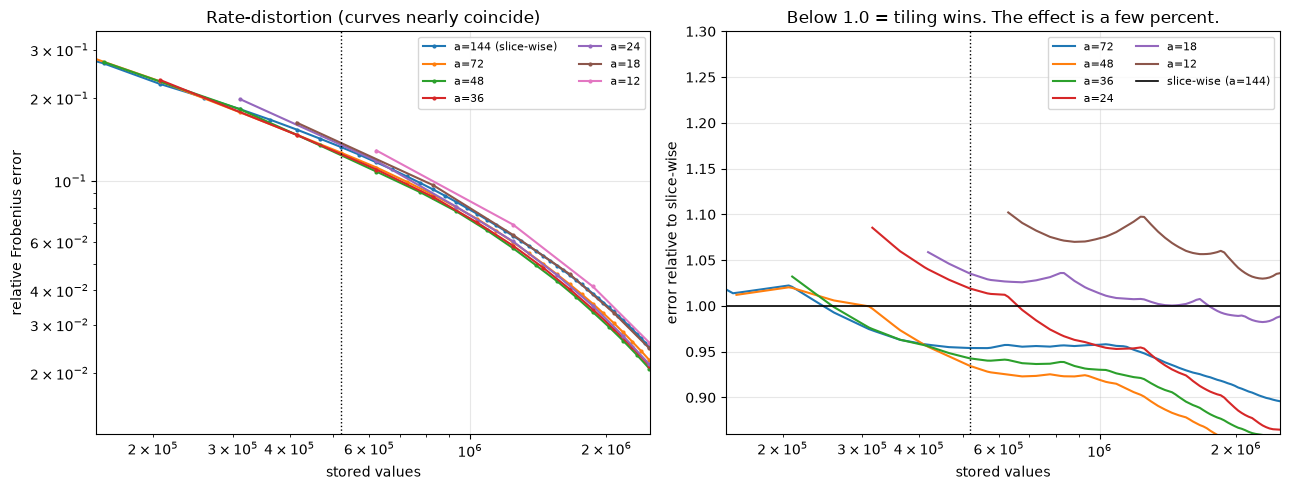

In [5]:
try:
    import matplotlib.pyplot as plt

    def interp_err(a, grid):
        c = np.array([p[0] for p in curves[a]], float)
        e = np.array([p[1] for p in curves[a]], float)
        out = np.full(len(grid), np.nan)
        ins = (grid >= c.min()) & (grid <= c.max())
        out[ins] = np.exp(np.interp(np.log(grid[ins]), np.log(c), np.log(e)))
        return out

    grid = np.logspace(np.log10(1.5e5), np.log10(2.5e6), 160)
    ref = interp_err(144, grid)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    for a in TILES:
        c = [p[0] for p in curves[a]]; e = [p[1] for p in curves[a]]
        ax1.plot(c, e, marker=".", ms=4,
                 label=f"a={a}" + (" (slice-wise)" if a == 144 else ""))
    ax1.axvline(BASE, color="k", ls=":", lw=1)
    ax1.set(xscale="log", yscale="log", xlim=(1.5e5, 2.5e6), ylim=(0.012, 0.35),
            xlabel="stored values", ylabel="relative Frobenius error",
            title="Rate-distortion (curves nearly coincide)")
    ax1.legend(ncol=2, fontsize=8); ax1.grid(alpha=.3)

    for a in TILES:
        if a == 144: continue
        ax2.plot(grid, interp_err(a, grid) / ref, label=f"a={a}")
    ax2.axhline(1.0, color="k", lw=1.2, label="slice-wise (a=144)")
    ax2.axvline(BASE, color="k", ls=":", lw=1)
    ax2.set(xscale="log", xlim=(1.5e5, 2.5e6), ylim=(0.86, 1.30),
            xlabel="stored values", ylabel="error relative to slice-wise",
            title="Below 1.0 = tiling wins. The effect is a few percent.")
    ax2.legend(ncol=2, fontsize=8); ax2.grid(alpha=.3)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed -- see the table above")

### What the measurement says

Moderate tiling **does** help, modestly, and the best tile size shrinks as the
budget grows. At a tight budget full slices win outright, because a tiled fit
cannot spend less than `r' = 1` per tile and so has a hard storage floor.

This is a real effect and it refines the analytical sketch: for a *plain SVD*
fit, cutting faces into tiles is mildly profitable in the 1x-2x storage range.
Natural images have lower local rank than global rank, which is the same reason
JPEG works on 8x8 blocks.

Three things this does not measure: blocking artifacts (Frobenius error is
blind to them -- see the reconstructions below), compute cost, and anything
about the *Hadamard* fit, which Section 4 shows behaves differently.

a=144  r'=10  storage   518,400 (1.00x base)  rel.err 0.1330


a=72   r'=5   storage   518,400 (1.00x base)  rel.err 0.1269


a=36   r'=2   storage   414,720 (0.80x base)  rel.err 0.1471
a=12   r'=1   storage   622,080 (1.20x base)  rel.err 0.1290


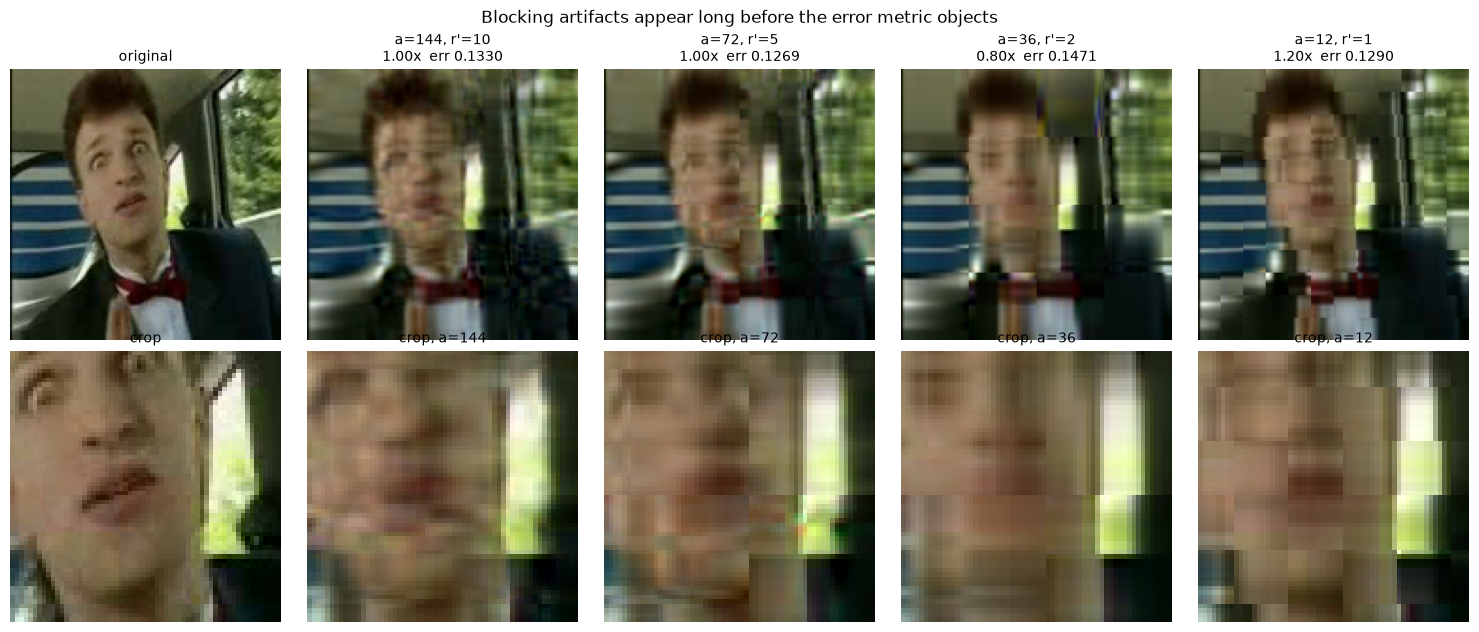

In [6]:
def reconstruct(a, rp):
    t = X.reshape(S, m // a, a, n // a, a).permute(0, 1, 3, 2, 4).reshape(-1, a, a)
    U, s, Vh = torch.linalg.svd(t, full_matrices=False)
    rp = min(rp, a)
    rec = (U[:, :, :rp] * s[:, None, :rp]) @ Vh[:, :rp, :]
    Y = rec.reshape(S, m // a, n // a, a, a).permute(0, 1, 3, 2, 4).reshape(S, m, n)
    cost = rp * 2 * a * (m // a) * (n // a) * S
    return Y, cost

FRAME = 30
settings = [(144, 10), (72, 5), (36, 2), (12, 1)]
recons = []
for a, rp in settings:
    Y, cost = reconstruct(a, rp)
    img = torch.stack([Y[FRAME * 3 + ch] for ch in range(3)], -1).clamp(0, 1).cpu()
    err = ((X - Y).norm() / X.norm()).item()
    recons.append((a, rp, cost, err, img))
    print(f"a={a:<4} r'={rp:<3} storage {cost:>9,} ({cost/BASE:.2f}x base)"
          f"  rel.err {err:.4f}")

try:
    import matplotlib.pyplot as plt
    orig = torch.stack([X[FRAME * 3 + ch] for ch in range(3)], -1).cpu()
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
    for col, (ax_t, ax_b) in enumerate(zip(axes[0], axes[1])):
        if col == 0:
            ax_t.imshow(orig); ax_t.set_title("original", fontsize=10)
            ax_b.imshow(orig[40:100, 40:100]); ax_b.set_title("crop", fontsize=10)
        else:
            a, rp, cost, err, img = recons[col - 1]
            ax_t.imshow(img)
            ax_t.set_title(f"a={a}, r'={rp}\n{cost/BASE:.2f}x  err {err:.4f}", fontsize=10)
            ax_b.imshow(img[40:100, 40:100])
            ax_b.set_title(f"crop, a={a}", fontsize=10)
        ax_t.axis("off"); ax_b.axis("off")
    plt.suptitle("Blocking artifacts appear long before the error metric objects",
                 fontsize=12)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed -- reconstruction stats above")

## 3. Why this does not carry over to the Hadamard fit

Everything above is the plain SVD. The Hadamard decomposition fits
`(W1 H1) o (W2 H2)` instead, and tiling interacts with it badly for two
reasons that have nothing to do with image statistics.

**Storage.** An `a x a` tile fitted at rank `r` stores `2r(a + a) = 4ra`
values against `a^2` for the raw tile. It only compresses when `a > 4r`.

**Expressiveness.** The whole selling point is that an elementwise product of
two rank-`r` factors reaches rank up to `r^2` (Prop. 3.3). But a tile's rank
cannot exceed `min(a, a) = a` whatever you do. Once `r^2 >= a` the bound is
vacuous and buys nothing.

   r  break-even a > 4r   r^2 saturates below   usable tile range on 144px
----------------------------------------------------------------------------
   2                  8                     4                         none
   5                 20                    25                       21..25
  10                 40                   100                      41..100
  25                100                   625                     101..144
  50                200                  2500                         none

At the paper's rank 10 the window is 41..100 px on a 144px frame --
so roughly a 2x2 tiling, and nothing like an 8x8 JPEG block.


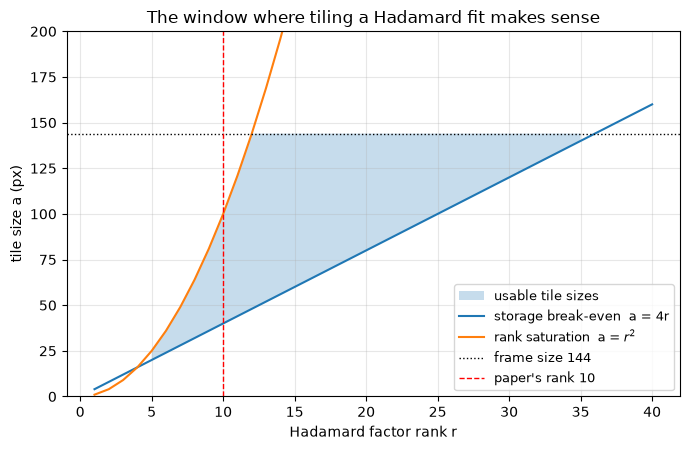

In [7]:
print(f"{'r':>4} {'break-even a > 4r':>18} {'r^2 saturates below':>21} "
      f"{'usable tile range on 144px':>28}")
print("-" * 76)
for r in [2, 5, 10, 25, 50]:
    lo, hi = 4 * r, r * r
    rng = f"{lo+1}..{min(hi, 144)}" if lo + 1 <= min(hi, 144) else "none"
    print(f"{r:>4} {lo:>18} {hi:>21} {rng:>28}")

print("\nAt the paper's rank 10 the window is 41..100 px on a 144px frame --")
print("so roughly a 2x2 tiling, and nothing like an 8x8 JPEG block.")

try:
    import matplotlib.pyplot as plt
    rs = np.arange(1, 41)
    fig, ax = plt.subplots(figsize=(7, 4.6))
    ax.fill_between(rs, 4 * rs, np.minimum(rs ** 2, 144),
                    where=(4 * rs < np.minimum(rs ** 2, 144)),
                    alpha=.25, label="usable tile sizes")
    ax.plot(rs, 4 * rs, label="storage break-even  a = 4r")
    ax.plot(rs, rs ** 2, label="rank saturation  a = $r^2$")
    ax.axhline(144, color="k", ls=":", lw=1, label="frame size 144")
    ax.axvline(10, color="r", ls="--", lw=1, label="paper's rank 10")
    ax.set(xlabel="Hadamard factor rank r", ylabel="tile size a (px)",
           ylim=(0, 200), title="The window where tiling a Hadamard fit makes sense")
    ax.legend(fontsize=9); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
except ImportError:
    pass

## 4. How the optimiser papers answer the same question

Shampoo and KFAC face the identical problem -- an operator too big to handle
whole -- and their answers map onto a single ladder, ordered by how much
correlation is kept:

| scheme | state | where |
|---|---|---|
| full | `m^2 n^2` | full-matrix AdaGrad; prohibitive |
| block-diagonal | sum over blocks | KFAC, one block per layer; Shampoo, one per tensor |
| Kronecker-factored | `m^2 + n^2` | Shampoo |
| diagonal | `m + n` | Adam; Shampoo's fallback above ~1200 |

Two details worth carrying back:

- Shampoo's answer to "this mode is too wide" is **diagonal, not blocks** (Sec.
  5, threshold ~1200, "no apparent sacrifice"). Splitting into fixed-size
  blocks is the *distributed* Shampoo line, a later paper not in `Literature/`.
- KFAC is the one that really does blocks-then-decomposition: block-diagonal by
  layer, each block Kronecker-factored as `A ⊗ B`.

Both block along a **structural boundary that already exists** -- a tensor, a
layer. Neither tiles geometrically. Applied back to the cube, the boundary that
already exists is the frontal slice, and Section 1 shows the paper is already
using it.

See `01-shampoo.ipynb` for the Shampoo implementation these come from.

## What this establishes, and what it does not

**Established here, measured on the Table 9 tensor:**

- The generalized Hadamard product with `M = I` is exactly facewise; slices are
  independent, so the cube is already blocked into 180 faces.
- For a plain SVD fit at matched storage, moderate tiling beats slice-wise by a
  few percent in the 1x-2x storage range, and the best tile size shrinks as the
  budget grows. At tighter budgets slice-wise wins.

**Not established:**

- **Nothing here tests the Hadamard fit.** Section 3 is arithmetic about
  storage and rank bounds, not a measurement. Running HadNet tiled would be the
  actual test, and at ~57 s per fit that is a real experiment, not a cell.
- **Frobenius error is not perceptual.** The reconstructions show visible
  blocking well before the metric reacts.
- **Compute cost is not measured.** Tiling makes each SVD cheaper but TSVD is
  already the fastest baseline at 0.2519 s; TAGD at 1193.6 s is the bottleneck.
- **Cross-slice redundancy is untouched.** `M = I` discards all of it by
  construction. That -- not tiling within a face -- is where the unexploited
  structure is, and it is the same instinct as the "shared basis + per-slice
  coefficients" note in `docs/RESEARCH.md`.